In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [23]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

1. Crosstab Analysis:

* Create a crosstab between the product category and the isBestSeller status.

* Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.


In [24]:
crosstab_result = pd.crosstab(df["category"], df["isBestSeller"])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [29]:
# Proportion of best-sellers for each category
new_crosstab_result = crosstab_result.copy ()
new_crosstab_result["ProportionBestSellers"] = crosstab_result[True] / (crosstab_result[True] + crosstab_result[False])

# Sort the categories based on the proportion in descending order
sorted_crosstab = new_crosstab_result.sort_values(by="ProportionBestSellers", ascending=False)

display(new_crosstab_result)

isBestSeller,False,True,ProportionBestSellers
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [ ]:
#There is no category where a best-seller is more prevalent. 

2. Statistical Tests:
* Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
* Compute Cramér's V to understand the strength of association between best-seller status and category.

In [30]:
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value 

(36540.20270061387, 0.0)

In [ ]:
# The null hypothesis of the Chi-square test is that the two categorical variables are independent.
# There"s a significant association between `category` and `isBestSeller` in the dataset.

In [31]:
from scipy.stats.contingency import association

# Computing the association between variables in "crosstab_result" using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

In [ ]:
# The Cramér's V value of 0.122 suggests a weak association between the two variables. 
# The strength of this relationship is not very strong.

3. Visualizations:

* Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

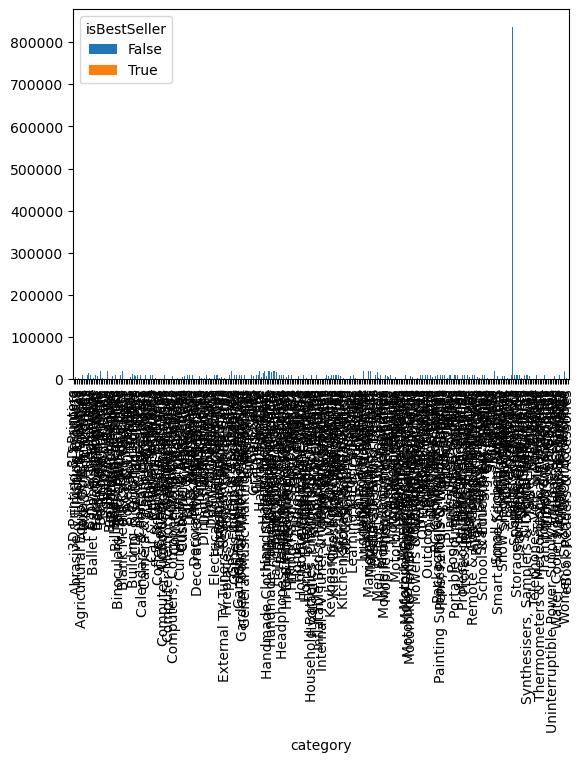

In [39]:
crosstab_result.plot(kind="bar", stacked=True);


In [ ]:
# This char isn't readable. Then I decided to filter the top 10 categories.

<Axes: xlabel='category'>

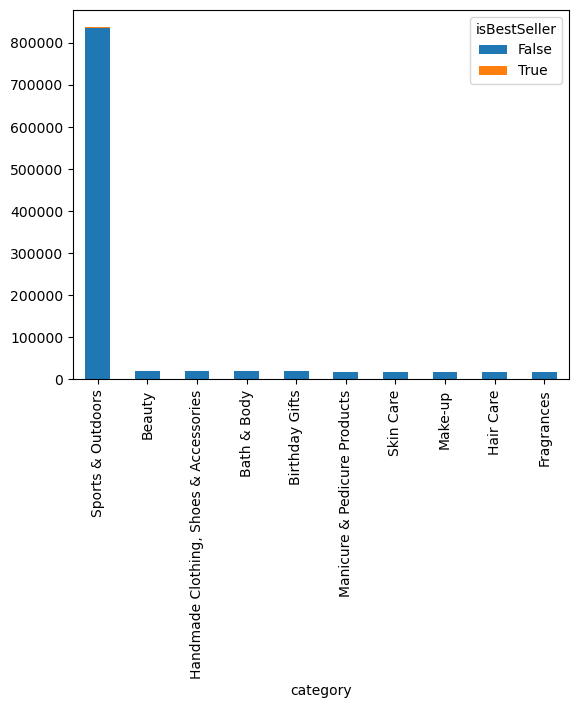

In [40]:
top_items = crosstab_result.sum(axis=1).nlargest(10).index
filtered_crosstab = crosstab_result.loc[top_items]
filtered_crosstab.plot(kind="bar", stacked=True)


## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [41]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [50]:
data_series = df["price"]  
outliers = tukeys_test_outliers(data_series)
df = df.loc[~df.index.isin(outliers.index)]
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing



1. Violin Plots:

* Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
* Which product category tends to have the highest median price? Don't filter here by top categories.

C:\Users\lored\AppData\Local\Temp\ipykernel_10648\2620760170.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data= top_20_df , x='price', y='category', palette="coolwarm", legend=False);


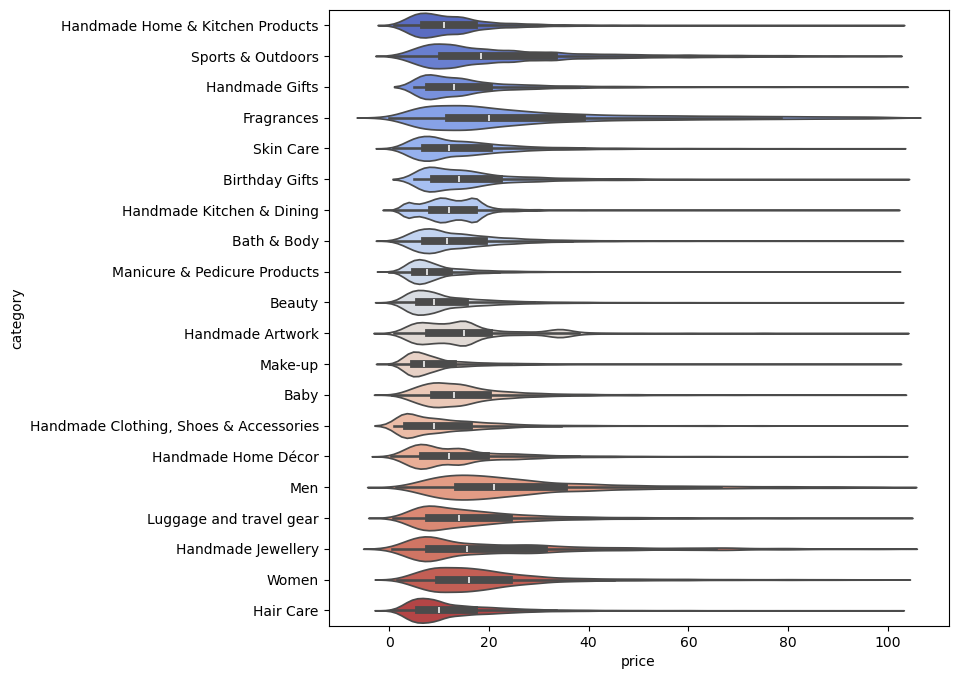

In [74]:
category_counts = df["category"].value_counts()
top_20_categories = category_counts.head(20).index

top_20_df = df[df["category"].isin(top_20_categories)]
plt.figure(figsize=(8,8))
sns.violinplot(data= top_20_df , x="price", y="category", palette="coolwarm", legend=False);


In [76]:
#median prices by category
median_prices = df.groupby("category")["price"].median()

highest_median_price_category = median_prices.idxmax()
highest_median_price = median_prices.max()

print (f"The category with the highest median price: " ,highest_median_price_category)
print (f"The highest median price: ", highest_median_price)

The category with the highest median price:  Desktop PCs
The highest median price:  74.0


2. Bar Charts:

* Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
* Which product category commands the highest average price? Don't filter here by top categories.

C:\Users\lored\AppData\Local\Temp\ipykernel_10648\2868924752.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_df, x="price", y="category", palette="coolwarm",  legend=False);


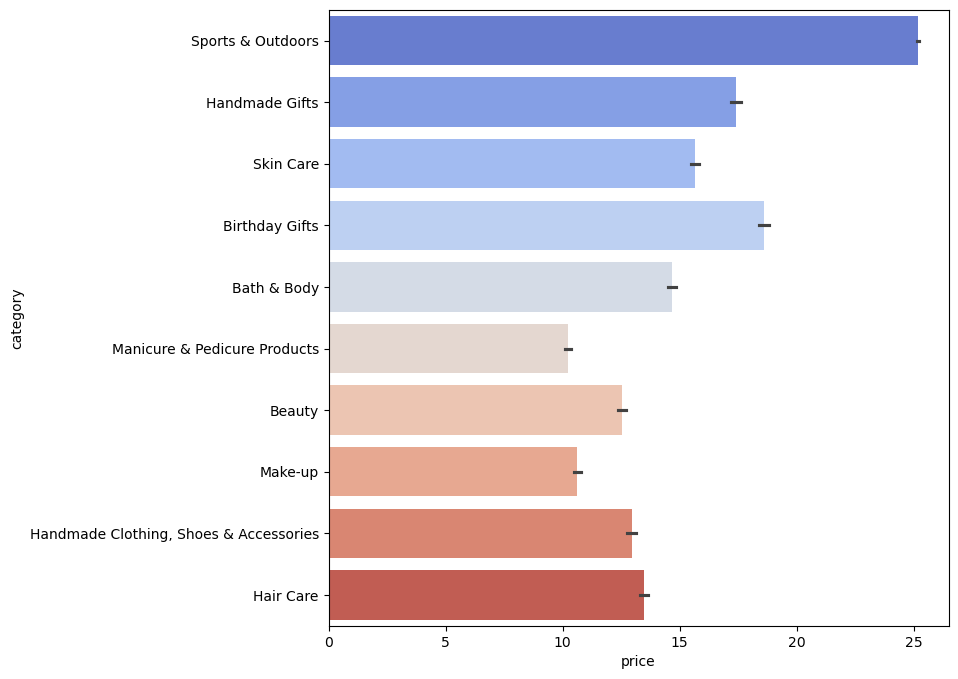

In [85]:
category_counts = df["category"].value_counts()
top_10_categories = category_counts.head(10).index

top_10_df = df[df["category"].isin(top_10_categories)]

plt.figure(figsize=(8,8))
sns.barplot(data=top_10_df, x="price", y="category", palette="coolwarm",  legend=False);



In [80]:
#avg prices by category
avg_prices = df.groupby("category")["price"].mean()

highest_avg_price_category = avg_prices.idxmax()
highest_avg_price = avg_prices.max()

print (f"The category with the highest average price: " ,highest_avg_price_category)
print (f"The highest average price: ", highest_avg_price)

The category with the highest average price:  Motherboards
The highest average price:  68.77243243243242


3. Box Plots:

* Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
* Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


C:\Users\lored\AppData\Local\Temp\ipykernel_10648\2549397478.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=top_10_df, x='stars', y='category', palette="coolwarm", legend=False);


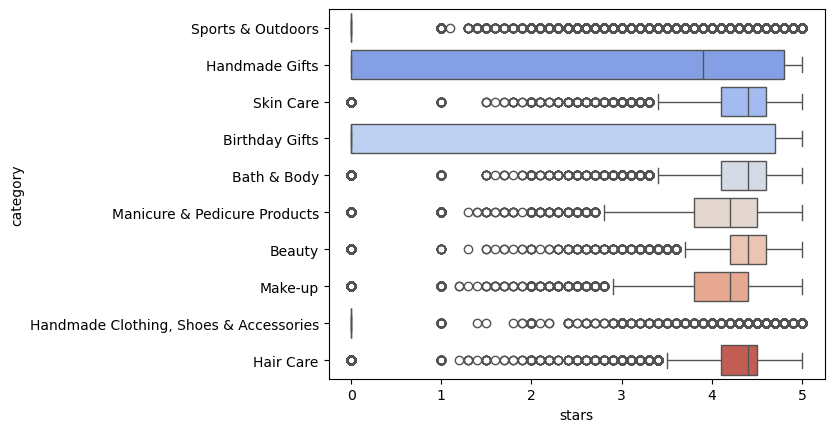

In [84]:
category_counts = df["category"].value_counts()
top_10_categories = category_counts.head(10).index

top_10_df = df[df["category"].isin(top_10_categories)]


sns.boxplot(data=top_10_df, x="stars", y="category", palette="coolwarm", legend=False);

In [82]:
#median ratings by category
median_ratings = df.groupby("category")["stars"].median()

highest_median_rating_category = median_ratings.idxmax()
highest_median_rating = median_ratings.max()

print (f"The category with the highest median rating: " ,highest_median_rating_category)
print (f"The highest median rating: ", highest_median_rating)

The category with the highest median rating:  Computer Memory
The highest median rating:  4.7


## Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

1. Correlation Coefficients:

* Calculate the correlation coefficient between price and stars.
* Is there a significant correlation between product price and its rating?

In [86]:
correlation = df["price"].corr(df["stars"])
correlation

-0.07767299878178476

In [ ]:
# The correlation value between price and stars suggest there is almost no linear relationship.

2. Visualizations:

* Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
* Use a correlation heatmap to visualize correlations between all numerical variables.
* Examine if product prices typically follow a normal distribution using a QQ plot.

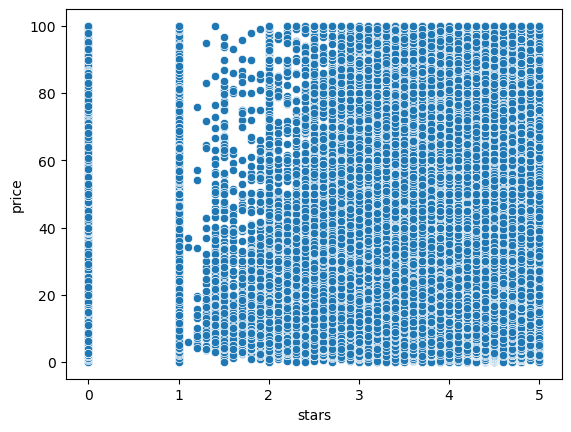

In [88]:
sns.scatterplot(data=df, x="stars", y="price");

In [ ]:
# For the rating of 0, prices are distributed in a wide range from 0 to 100. 
# This suggests that there are many products or services without any star rating but varying prices.
# From 1 the range of prices starts to become more evenly spread. 


In [91]:
# Separating between discrete and continuous variables, as discrete ones could potentially be treated as categorical.
# Remember to adjust the threshold (in this case, < 20) based on your dataset's specific characteristics and domain knowledge.
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
potential_categorical_from_numerical

""
0
1
2
3
4
...
2443646
2443647
2443648
2443649


In [92]:
# Extracting columns with object (typically string) data types to create a categorical dataframe
# For demonstration purposes, let's consider the columns in potential_categorical_from_numerical as categorical variables.
df_categorical = pd.concat([df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

# Adjusting the numerical dataframe by removing the moved columns
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

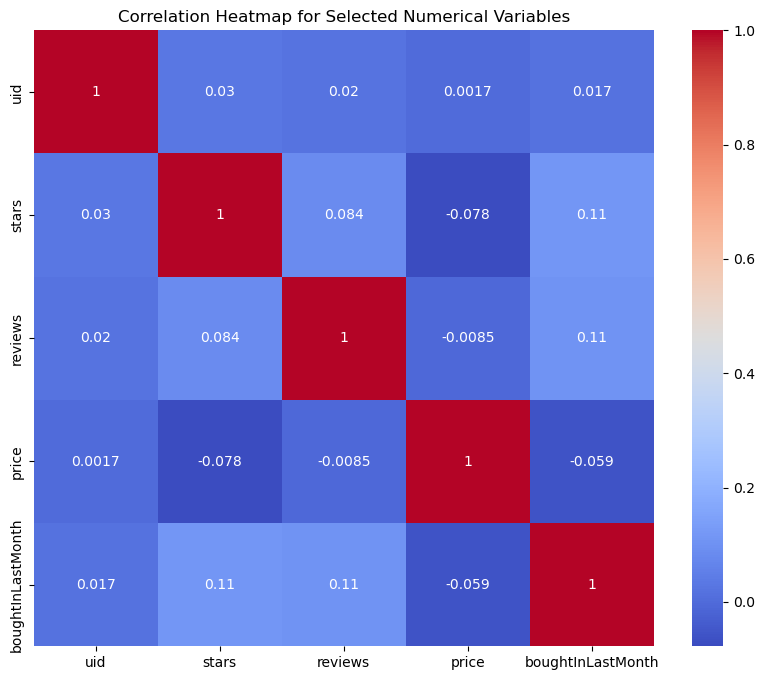

In [94]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(10,8))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

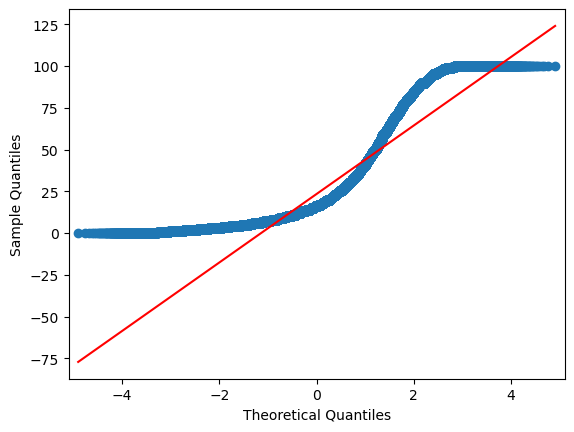

In [97]:
import statsmodels.api as sm

sm.qqplot(df["price"], line='s');

In [ ]:
#It seems that the data has heavier tails than the comparison distribution.